In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import plot
import stats
import sham
import cam
from multicam.multicam import MultiCAM
from halotools.mock_observables import return_xyz_formatted_array, tpcf_jackknife

TNG_H = 0.6774
COLOR_CUT = 1.0  # Changed a little bit

In [2]:
# Stellar mass units Msun / h
# Mpeak units Msun / h

In [3]:
### Import cache file hydro ###
hydro_path = 'data/cache_files/hydro_color_tree_no_subhaloflag_check_data.csv'
hydro_data = pd.read_csv(hydro_path, usecols=['SubhaloFlag', 'SubhaloMass', 'StellarMass', 'x', 'y', 'z',
                                              'logStellarMass', 'logSubhaloMass', 'g-i',
                                              'mpeak', 'a12', *[f'mpeak_mah{ii}' for ii in range(100)]])


In [4]:
hydro_data

,SubhaloMass,SubhaloFlag,StellarMass,x,y,z,logSubhaloMass,logStellarMass,a12,mpeak,...,mpeak_mah91,mpeak_mah92,mpeak_mah93,mpeak_mah94,mpeak_mah95,mpeak_mah96,mpeak_mah97,mpeak_mah98,mpeak_mah99,g-i
0,2.747794e+14,True,1.638342e+12,0.849091,26.326996,18.306934,14.438984,12.214405,0.657895,2.747794e+14,...,0.790409,0.818398,0.859956,0.886212,0.908843,0.935107,0.951342,0.984261,1.0,1.220444
1,3.666623e+13,True,2.573102e+11,0.106473,24.633322,16.900553,13.564266,11.410457,0.787402,3.730176e+13,...,0.812616,0.837212,0.866757,0.905420,0.930965,0.951276,0.963505,1.000000,1.0,1.159128
2,7.734555e+12,True,2.885268e+11,0.853112,26.725748,17.510680,12.888435,11.460186,0.694444,4.183134e+13,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.143808
3,3.253667e+12,True,6.276475e+10,0.768784,26.518290,15.530523,12.512373,10.797716,0.395257,3.625978e+12,...,0.971726,0.981165,0.989442,0.996482,0.997535,1.000000,1.000000,1.000000,1.0,1.135096
4,2.980181e+12,True,8.770330e+10,1.426592,26.341442,19.041204,12.474242,10.943016,0.364964,4.653012e+12,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.124866
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101426,3.134561e+08,True,0.000000e+00,10.962378,18.350170,63.844173,8.496177,-inf,0.374532,3.029314e+10,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,NaN
101427,2.148872e+08,True,2.063207e+06,19.073679,67.058760,0.137797,8.332211,6.314543,0.212314,1.022531e+10,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,0.963495
101428,1.900112e+08,True,1.928753e+06,40.783150,72.029335,42.676410,8.278779,6.285276,0.301205,1.815778e+10,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,0.940955
101429,1.718953e+08,True,0.000000e+00,22.492498,35.048150,43.090714,8.235264,-inf,0.212314,1.070421e+10,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,NaN


In [5]:
import corner
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

# Define unmatched params
a12_unmatched = hydro_data['a12']
mpeak_unmatched = hydro_data['mpeak']
color_unmatched = hydro_data['g-i']
stellarmass_unmatched = hydro_data['StellarMass']
subhalomass_unmatched = hydro_data['SubhaloMass']
subhaloflag = hydro_data['SubhaloFlag']

data = hydro_data.copy()   # avoid modifying original

data['a12'] = a12_unmatched
data['mpeak'] = mpeak_unmatched
data['color'] = color_unmatched
data['StellarMass'] = stellarmass_unmatched
data['SubhaloMass'] = subhalomass_unmatched
data['SubhaloFlag'] = subhaloflag


match_path = 'data/match_data/matches-trees-tng100.npz'

with open(match_path, 'rb') as fp:
    # file containing matching information
    match_dict = np.load(fp, allow_pickle=True)
    print("matches_bar length: ", len(match_dict['matches_bar']))

    # boolean array corresponding to whether each halo in the hydro data is matched or not
    match_hydro = match_dict['matches_bar']

# get mask of matched quantities
mask_hydro_match = match_hydro != -1 # "-1" corresponds to unmatched haloes


# matched subsets
data['a12_matched']         = a12_unmatched[mask_hydro_match]
data['mpeak_matched']       = mpeak_unmatched[mask_hydro_match]
data['color_matched']       = color_unmatched[mask_hydro_match]
data['stellarmass_matched'] = stellarmass_unmatched[mask_hydro_match]
data['subhalomass_matched'] = subhalomass_unmatched[mask_hydro_match]

print("Data length w/o cuts", len(data))

data = data[data['SubhaloFlag'] == 1]
print("Data length w/ subhaloflag cut", len(data))

data = data[data['StellarMass'] >= 1.4 * 10**8 * TNG_H]
print("Data length w/ min number stellar mass particles", len(data))


data = data[data['subhalomass_matched'] > 0]
data = data[data['stellarmass_matched'] > 0]

matches_bar length:  101431
Data length w/o cuts 101431
Data length w/ subhaloflag cut 101364
Data length w/ min number stellar mass particles 29365


In [6]:
hydro_data_mpeak_cut = data[(data['mpeak_matched'] >= (10**11))&(data['mpeak_matched'] <= (10**12))]
print(len(hydro_data_mpeak_cut))

10559


In [7]:
hydro_mstar_mpeak_cut = data[(np.log10(data['stellarmass_matched']) > 9.5) & (np.log10(data['stellarmass_matched']) < 10.2)]
print(len(hydro_mstar_mpeak_cut))

3827


In [8]:
from multicam_tng_utils import get_msmhmr

In [9]:
log10_stellar_mass = np.array(np.log10(hydro_data_mpeak_cut['stellarmass_matched']))
log10_mpeak = np.array(np.log10(hydro_data_mpeak_cut['mpeak_matched']))

m_star_dev, (m, b) = get_msmhmr(log10_stellar_mass, 
                                log10_mpeak,
                                mass_bin = (11, 12), n_bins = 11)
print(m_star_dev, (m, b))

[-0.03895806  0.09968563 -0.09038291 ...  0.22567343  0.13283112
 -0.07381422] (np.float64(0.5353597543249119), np.float64(-7.990175626140006))


In [10]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set global font size for all text elements (optional, can be overridden)
mpl.rcParams['font.size'] = 25

# Set global font size for axis labels
mpl.rcParams['axes.labelsize'] = 30

# Set global font size for tick numbers
mpl.rcParams['xtick.labelsize'] = 20
mpl.rcParams['ytick.labelsize'] = 20

# Set tick widths and sizes globally
mpl.rcParams['xtick.major.width'] = 3
mpl.rcParams['ytick.major.width'] = 3
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['ytick.major.size'] = 5

# Set axes line width globally
mpl.rcParams['axes.linewidth'] = 3 # Sets the width of the spines

In [11]:
hydro_data_mpeak_cut

,SubhaloMass,SubhaloFlag,StellarMass,x,y,z,logSubhaloMass,logStellarMass,a12,mpeak,...,mpeak_mah97,mpeak_mah98,mpeak_mah99,g-i,color,a12_matched,mpeak_matched,color_matched,stellarmass_matched,subhalomass_matched
15,6.426670e+11,True,1.959215e+10,0.379645,25.079288,16.587719,11.807986,10.292082,0.500000,8.567395e+11,...,1.0,1.0,1.0,1.002523,1.002523,0.500000,8.567395e+11,1.002523,1.959215e+10,6.426670e+11
20,3.942948e+11,True,2.328852e+10,0.303943,27.653301,17.940432,11.595821,10.367142,0.645161,7.788175e+11,...,1.0,1.0,1.0,1.008192,1.008192,0.645161,7.788175e+11,1.008192,2.328852e+10,3.942948e+11
21,3.774756e+11,True,1.898052e+10,74.735700,24.650198,16.704525,11.576889,10.278308,0.483092,9.065073e+11,...,1.0,1.0,1.0,1.159027,1.159027,0.483092,9.065073e+11,1.159027,1.898052e+10,3.774756e+11
22,4.092979e+11,True,1.634936e+10,1.857714,25.990385,19.931873,11.612040,10.213501,0.344828,5.439045e+11,...,1.0,1.0,1.0,1.041630,1.041630,0.344828,5.439045e+11,1.041630,1.634936e+10,4.092979e+11
23,2.735071e+11,True,2.056505e+10,0.719776,26.065008,17.520130,11.436969,10.313129,0.374532,7.002170e+11,...,1.0,1.0,1.0,0.732254,0.732254,0.374532,7.002170e+11,0.732254,2.056505e+10,2.735071e+11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58365,2.355737e+10,True,2.111694e+09,51.652386,10.073790,12.564201,10.372127,9.324631,0.256410,1.304823e+11,...,1.0,1.0,1.0,1.113102,1.113102,0.256410,1.304823e+11,1.113102,2.111694e+09,2.355737e+10
60625,2.968423e+10,True,7.676879e+08,1.785950,52.558304,54.282352,10.472526,8.885184,0.414938,1.365173e+11,...,1.0,1.0,1.0,0.995693,0.995693,0.414938,1.365173e+11,0.995693,7.676879e+08,2.968423e+10
61580,2.030373e+10,True,1.947287e+09,43.591217,66.893105,46.197330,10.307576,9.289430,0.249377,1.280709e+11,...,1.0,1.0,1.0,1.108538,1.108538,0.249377,1.280709e+11,1.108538,1.947287e+09,2.030373e+10
62402,2.186401e+10,True,1.521510e+09,2.042494,25.050950,18.758776,10.339729,9.182275,0.212314,1.253511e+11,...,1.0,1.0,1.0,1.134243,1.134243,0.212314,1.253511e+11,1.134243,1.521510e+09,2.186401e+10


In [12]:
# Define Targets & features
color = hydro_data_mpeak_cut['color_matched']
targets = np.array([color, m_star_dev]).T
mah = np.array([hydro_data_mpeak_cut[f'mpeak_mah{ii}'] for ii in range(100)]).T
features = mah
print(targets.shape, features.shape)

(10559, 2) (10559, 100)


In [13]:
n_features = 100
n_targets = 2
model = MultiCAM(n_features, n_targets)

In [14]:
model.fit(features, targets)

In [15]:
pred = model.predict(features)

In [16]:
pred.shape

(10559, 2)

In [17]:
# Truth
mpeak = np.array(np.log10(hydro_data_mpeak_cut['mpeak_matched']))
mstar_truth = m_star_dev + np.log10(10 ** (m * mpeak + b) * 10**mpeak)

# MultiCAM
m_star_dev_pred = pred[:, 1]
mstar_pred = m_star_dev_pred + np.log10(10 ** (m * mpeak + b) * 10**mpeak)

In [18]:
print(mstar_pred)

[10.39144202 10.15487274 10.41352347 ...  9.42843739  9.4746195
  9.20382894]


In [19]:
hydro_full = pd.read_csv('data/cache_files/hydro_color_tree_subhaloflag_check_data.csv', usecols=['SubhaloMass', 'StellarMass', 'x', 'y', 'z',
                                                                           'logStellarMass', 'logSubhaloMass', 'g-i'])
print("\nHydro Table")
print(len(hydro_full))
print("\nCache files read in!")

# 1.4 * 10^8 minimum on Stellar Mass for hydro catalog
hydro_full = hydro_full[hydro_full['StellarMass'] >= (1.4 * 10**8 * TNG_H)]
print("\nNew Hydro Table Length:")
print(len(hydro_full))


Hydro Table
101364

Cache files read in!

New Hydro Table Length:
29365


In [20]:
## Compute TPCF ###
from halotools.mock_observables import return_xyz_formatted_array, tpcf_jackknife

def generate_randoms(Lbox, number):
    """Generate randoms to be used for tpcf_jackknife
    Args:
        Lbox: size of TNG simulation box
        number: desired number of randoms, i.e. 10,000
    Return:
        Nran: xyz formatted array of uniform random variables
    """
    Xran = np.random.uniform(0, Lbox, number)
    Yran = np.random.uniform(0, Lbox, number)
    Zran = np.random.uniform(0, Lbox, number)
    Nran = return_xyz_formatted_array(Xran, Yran, Zran)
    return Nran

## Look at mstar between 9.3 and 10
## Kuan suggests use: 9.5 to 10.2
# Note hydro_full for truth (no unness cuts)
hydro_mstar_cut = hydro_full[(np.log10(hydro_full['StellarMass']) > 9.5) & (np.log10(hydro_full['StellarMass']) < 10.2)]

# Note use mpeak_cut cause that's what we apply mcam to
hydro_data_mpeak_cut['pred_color'] = pred[:, 0]
hydro_mstar_pred = hydro_data_mpeak_cut[(mstar_pred > 9.5) & (mstar_pred < 10.2)]

Lbox = 110.7 * TNG_H
rbins = np.logspace(np.log10(0.1), np.log10(24.9), 16)
rbin_centers = 0.5 * (rbins[1:] + rbins[:-1])
randoms = generate_randoms(Lbox, 50000)
# Kuan: use more randoms...

/tmp/ipykernel_7074/2380616677.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hydro_data_mpeak_cut['pred_color'] = pred[:, 0]


In [21]:
print(len(hydro_mstar_cut), len(hydro_mstar_pred))

4054 3365


In [22]:
xi_truth, cov_truth = tpcf_jackknife(
        return_xyz_formatted_array(hydro_mstar_cut['x'], hydro_mstar_cut['y'], hydro_mstar_cut['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_pred, cov_pred = tpcf_jackknife(
        return_xyz_formatted_array(hydro_mstar_pred['x'], hydro_mstar_pred['y'], hydro_mstar_pred['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

In [23]:
red_pred = hydro_mstar_pred[hydro_mstar_pred['pred_color'] > COLOR_CUT]
blue_pred = hydro_mstar_pred[hydro_mstar_pred['pred_color'] <= COLOR_CUT]

red_table = hydro_mstar_cut[hydro_mstar_cut['g-i'] > COLOR_CUT]
blue_table = hydro_mstar_cut[hydro_mstar_cut['g-i'] <= COLOR_CUT]

print(len(red_pred), len(blue_pred), len(red_table), len(blue_table))

685 2680 983 3071


In [24]:
## Compute TPCF ###
from halotools.mock_observables import return_xyz_formatted_array, tpcf_jackknife

Lbox = 110.7 * TNG_H
rbins = np.logspace(np.log10(0.1), np.log10(24.9), 16)
rbin_centers = 0.5 * (rbins[1:] + rbins[:-1])
randoms = generate_randoms(Lbox, 50000)


xi_red_truth, cov_red_truth = tpcf_jackknife(
        return_xyz_formatted_array(red_table['x'], red_table['y'], red_table['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_blue_truth, cov_blue_truth = tpcf_jackknife(
        return_xyz_formatted_array(blue_table['x'], blue_table['y'], blue_table['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_red_pred, cov_red_pred = tpcf_jackknife(
        return_xyz_formatted_array(red_pred['x'], red_pred['y'], red_pred['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_blue_pred, cov_blue_pred = tpcf_jackknife(
        return_xyz_formatted_array(blue_pred['x'], blue_pred['y'], blue_pred['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

# CAM:

In [25]:

hydro_full = pd.read_csv('data/cache_files/hydro_color_tree_subhaloflag_check_data.csv', usecols=['SubhaloMass', 'StellarMass', 'x', 'y', 'z',
                                                                           'logStellarMass', 'logSubhaloMass', 'g-i'])
print("\nHydro Table")
print(len(hydro_full))
print("\nCache files read in!")

# 1.4 * 10^8 minimum on Stellar Mass for hydro catalog
hydro_full = hydro_full[hydro_full['StellarMass'] >= (1.4 * 10**8 * TNG_H)]
print("\nNew Hydro Table Length:")
print(len(hydro_full))

# Pick top whatever of DMO and then do SHAM
data = data.sort_values('mpeak', ascending=False).head(len(hydro_full))

# Add z12 column to dmo_full

data['z12'] = (1 / data['a12_matched']) - 1


Hydro Table
101364

Cache files read in!

New Hydro Table Length:
29365


In [26]:
data

,SubhaloMass,SubhaloFlag,StellarMass,x,y,z,logSubhaloMass,logStellarMass,a12,mpeak,...,mpeak_mah98,mpeak_mah99,g-i,color,a12_matched,mpeak_matched,color_matched,stellarmass_matched,subhalomass_matched,z12
0,2.747794e+14,True,1.638342e+12,0.849091,26.326996,18.306934,14.438984,12.214405,0.657895,2.747794e+14,...,0.984261,1.0,1.220444,1.220444,0.657895,2.747794e+14,1.220444,1.638342e+12,2.747794e+14,0.52
981,2.746362e+14,True,9.690504e+11,19.755348,47.554966,48.920635,14.438758,11.986346,0.847458,2.746362e+14,...,0.990073,1.0,1.238195,1.238195,0.847458,2.746362e+14,1.238195,9.690504e+11,2.746362e+14,0.18
1010,3.894857e+10,True,3.054394e+10,19.644720,47.875004,48.838127,10.590491,10.484925,0.952381,2.492563e+14,...,1.000000,1.0,1.288086,1.288086,0.952381,2.492563e+14,1.288086,3.054394e+10,3.894857e+10,0.05
982,5.752552e+12,True,3.892191e+11,20.128317,48.514076,48.597427,12.759861,11.590194,0.934579,2.445018e+14,...,1.000000,1.0,1.110487,1.110487,0.934579,2.445018e+14,1.110487,3.892191e+11,5.752552e+12,0.07
1760,2.321133e+14,True,1.242556e+12,10.900232,50.857914,47.590435,14.365700,12.094316,0.645161,2.321133e+14,...,0.995120,1.0,1.184904,1.184904,0.645161,2.321133e+14,1.184904,1.242556e+12,2.321133e+14,0.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99154,1.007057e+10,True,1.029483e+08,18.532185,12.871834,5.824638,10.003054,8.012619,0.133511,1.336224e+10,...,1.000000,1.0,1.037847,1.037847,0.133511,1.336224e+10,1.037847,1.029483e+08,1.007057e+10,6.49
561,4.554931e+09,True,9.681404e+07,0.313810,25.627014,17.703558,9.658482,7.985938,0.193050,1.322374e+10,...,1.000000,1.0,1.018293,1.018293,0.193050,1.322374e+10,1.018293,9.681404e+07,4.554931e+09,4.18
34673,8.569547e+08,True,1.076233e+08,8.685472,22.144790,23.523277,8.932958,8.031906,0.233645,1.276082e+10,...,1.000000,1.0,0.348774,0.348774,0.233645,1.276082e+10,0.348774,1.076233e+08,8.569547e+08,3.28
7166,2.140581e+09,True,2.116128e+08,52.385815,71.136116,41.617214,9.330532,8.325541,0.193050,1.268962e+10,...,1.000000,1.0,1.044357,1.044357,0.193050,1.268962e+10,1.044357,2.116128e+08,2.140581e+09,4.18


In [27]:
low = 9.5
high = 10.2
color_bin_cam, color_pred_cam, mask_gal, mask_halo = cam.cam(
        np.log10(data['mpeak_matched'].to_numpy()), 
        np.log10(hydro_full['StellarMass'].to_numpy()), 
        data['z12'].to_numpy(), 
        hydro_full['g-i'].to_numpy(), 
        low, high)

In [28]:
halo_bin = data[mask_halo].copy()
hydro_bin = hydro_full[mask_gal].copy()
halo_bin['color_pred_cam'] = color_pred_cam
hydro_bin['color'] = color_bin_cam
halo_bin

,SubhaloMass,SubhaloFlag,StellarMass,x,y,z,logSubhaloMass,logStellarMass,a12,mpeak,...,mpeak_mah99,g-i,color,a12_matched,mpeak_matched,color_matched,stellarmass_matched,subhalomass_matched,z12,color_pred_cam
1011,6.729176e+10,True,1.923009e+10,19.776539,47.404827,49.046745,10.827962,10.283981,0.344828,6.941293e+11,...,1.0,1.190123,1.190123,0.344828,6.941293e+11,1.190123,1.923009e+10,6.729176e+10,1.90,1.008395
30847,6.940093e+11,True,2.240284e+10,32.682117,58.487564,42.995910,11.841365,10.350303,0.364964,6.940093e+11,...,1.0,1.100454,1.100454,0.364964,6.940093e+11,1.100454,2.240284e+10,6.940093e+11,1.74,0.909242
10737,2.037265e+11,True,2.145386e+10,68.456260,35.077797,2.120961,11.309048,10.331506,0.423729,6.940089e+11,...,1.0,1.063812,1.063812,0.423729,6.940089e+11,1.063812,2.145386e+10,2.037265e+11,1.36,0.792178
4446,2.666836e+11,True,2.085087e+10,37.106438,0.742062,70.177956,11.425997,10.319124,0.311526,6.933917e+11,...,1.0,1.163988,1.163988,0.311526,6.933917e+11,1.163988,2.085087e+10,2.666836e+11,2.21,1.128624
31226,6.933662e+11,True,1.438627e+10,27.785934,0.869167,74.479880,11.840962,10.157948,0.249377,6.933662e+11,...,1.0,1.213070,1.213070,0.249377,6.933662e+11,1.213070,1.438627e+10,6.933662e+11,3.01,1.183044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37303,2.134361e+11,True,1.754192e+09,9.302565,41.528473,52.868843,11.329268,9.244077,0.568182,2.209533e+11,...,1.0,0.760300,0.760300,0.568182,2.209533e+11,0.760300,1.754192e+09,2.134361e+11,0.76,0.636354
2458,5.498651e+10,True,2.376954e+09,68.004360,57.611588,54.144455,10.740256,9.376020,0.400000,2.209512e+11,...,1.0,0.917664,0.917664,0.400000,2.209512e+11,0.917664,2.376954e+09,5.498651e+10,1.50,0.823708
9973,2.473102e+10,True,6.426376e+09,53.397495,69.092090,26.733036,10.393242,9.807966,0.249377,2.209241e+11,...,1.0,1.172800,1.172800,0.249377,2.209241e+11,1.172800,6.426376e+09,2.473102e+10,3.01,1.181588
1793,5.615045e+10,True,9.186174e+09,11.425529,50.538864,47.952133,10.749353,9.963135,0.233645,2.208993e+11,...,1.0,1.166748,1.166748,0.233645,2.208993e+11,1.166748,9.186174e+09,5.615045e+10,3.28,1.205384


In [29]:
import numpy as np
from halotools.mock_observables import tpcf_jackknife
from halotools.mock_observables import return_xyz_formatted_array

# ---------------------------------------------------
# Color split
# ---------------------------------------------------

halo_bin['red_pred_cam'] = halo_bin['color_pred_cam'].where(
    halo_bin['color_pred_cam'] > COLOR_CUT
)

halo_bin['blue_pred_cam'] = halo_bin['color_pred_cam'].where(
    halo_bin['color_pred_cam'] <= COLOR_CUT
)


# ---------------------------------------------------
# Random catalog
# ---------------------------------------------------

def generate_randoms(Lbox, number):
    """Generate randoms for tpcf_jackknife."""
    Xran = np.random.uniform(0, Lbox, number)
    Yran = np.random.uniform(0, Lbox, number)
    Zran = np.random.uniform(0, Lbox, number)
    return return_xyz_formatted_array(Xran, Yran, Zran)

randoms = generate_randoms(Lbox, 50_000)
print("\nGenerated 50000 randoms.")

# ---------------------------------------------------
# Masks (correct NaN handling)
# ---------------------------------------------------

mask_red = halo_bin['red_pred_cam'].notna()
mask_blue = halo_bin['blue_pred_cam'].notna()

# ---------------------------------------------------
# Build xyz arrays
# ---------------------------------------------------

xyz_red = return_xyz_formatted_array(
    halo_bin.loc[mask_red, 'x'].to_numpy(),
    halo_bin.loc[mask_red, 'y'].to_numpy(),
    halo_bin.loc[mask_red, 'z'].to_numpy(),
)

xyz_blue = return_xyz_formatted_array(
    halo_bin.loc[mask_blue, 'x'].to_numpy(),
    halo_bin.loc[mask_blue, 'y'].to_numpy(),
    halo_bin.loc[mask_blue, 'z'].to_numpy(),
)

# ---------------------------------------------------
# Two-point correlation functions
# ---------------------------------------------------

xi_red_cam, cov_red_cam = tpcf_jackknife(
    xyz_red,
    randoms,
    rbins,
    Nsub=3,
    period=Lbox,
    num_threads='max'
)

xi_blue_cam, cov_blue_cam = tpcf_jackknife(
    xyz_blue,
    randoms,
    rbins,
    Nsub=3,
    period=Lbox,
    num_threads='max'
)



Generated 50000 randoms.


In [30]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set global font size for all text elements (optional, can be overridden)
mpl.rcParams['font.size'] = 20

# Set global font size for axis labels
mpl.rcParams['axes.labelsize'] = 25

# Set global font size for tick numbers
mpl.rcParams['xtick.labelsize'] = 25
mpl.rcParams['ytick.labelsize'] = 25

# Set tick widths and sizes globally
mpl.rcParams['xtick.major.width'] = 3
mpl.rcParams['ytick.major.width'] = 3
mpl.rcParams['xtick.minor.width'] = 3
mpl.rcParams['ytick.minor.width'] = 3

mpl.rcParams['xtick.minor.size'] = 6
mpl.rcParams['ytick.minor.size'] = 6
mpl.rcParams['xtick.major.size'] = 7
mpl.rcParams['ytick.major.size'] = 7

# Set axes line width globally
mpl.rcParams['axes.linewidth'] = 3 # Sets the width of the spines

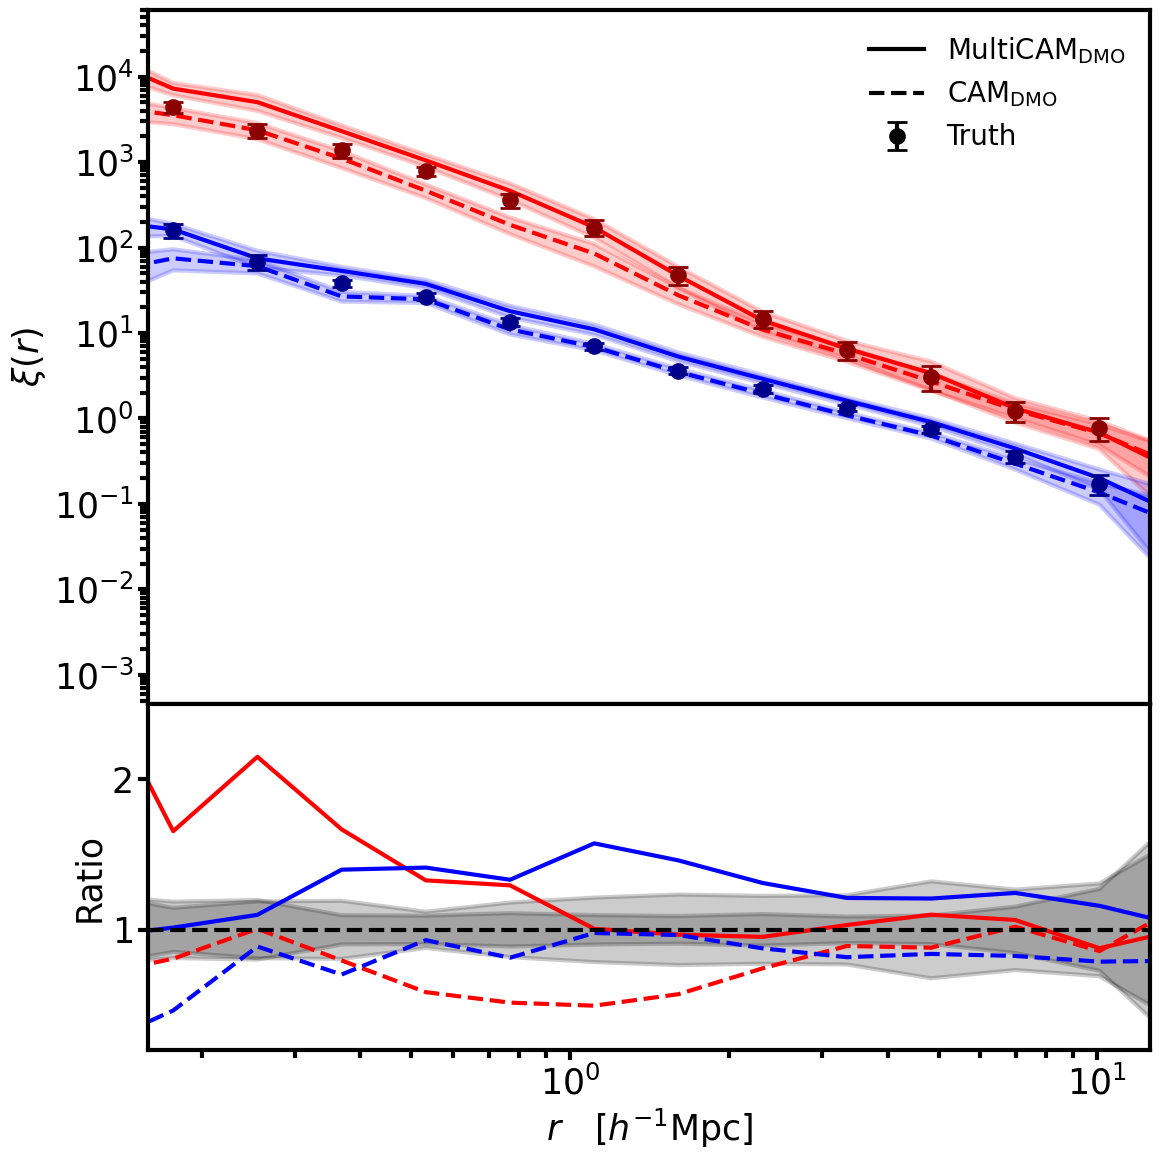

In [33]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 12),
    sharex=True,
    gridspec_kw={
        'height_ratios': [2, 1],
        'hspace': 0
    }
)
# ---------------- Top panel ----------------

#####################################

axes[0].plot(
    rbin_centers, xi_red_pred,
    color='red', linewidth=3
)
axes[0].fill_between(
    rbin_centers,
    xi_red_pred - np.sqrt(np.diag(cov_red_pred)),
    xi_red_pred + np.sqrt(np.diag(cov_red_pred)),
    color='red', alpha=0.2, linewidth=3
)

#####################################

axes[0].plot(
    rbin_centers, xi_blue_pred,
    color='blue', linewidth=3
)
axes[0].fill_between(
    rbin_centers,
    xi_blue_pred - np.sqrt(np.diag(cov_blue_pred)),
    xi_blue_pred + np.sqrt(np.diag(cov_blue_pred)),
    color='blue', alpha=0.2, linewidth=3
)

#####################################

axes[0].plot(
    rbin_centers, xi_red_cam,
    color='red', linestyle = '--', linewidth=3
)
axes[0].fill_between(
    rbin_centers,
    xi_red_cam - np.sqrt(np.diag(cov_red_cam)),
    xi_red_cam + np.sqrt(np.diag(cov_red_cam)),
    color='red', alpha=0.2, linewidth=3
)

#####################################

axes[0].plot(
    rbin_centers, xi_blue_cam,
    color='blue', linestyle = '--', linewidth=3
)
axes[0].fill_between(
    rbin_centers,
    xi_blue_cam - np.sqrt(np.diag(cov_blue_cam)),
    xi_blue_cam + np.sqrt(np.diag(cov_blue_cam)),
    color='blue', alpha=0.2, linewidth=3
)

###################################################



# Common errorbar style
err_kwargs = dict(
    fmt='o',
    markersize=10,
    color='darkred',
    elinewidth=3,
    capsize=7,
    capthick=3,
    markeredgewidth=2,
    alpha=1.0
)

axes[0].errorbar(
    rbin_centers, xi_red_truth,
    yerr=np.sqrt(np.diag(cov_red_truth)),
    **err_kwargs
)


# Common errorbar style
err_kwargs = dict(
    fmt='o',
    markersize=10,
    color='darkblue',
    elinewidth=3,
    capsize=7,
    capthick=3,
    markeredgewidth=2,
    alpha=1.0
)

axes[0].errorbar(
    rbin_centers, xi_blue_truth,
    yerr=np.sqrt(np.diag(cov_blue_truth)),
    **err_kwargs
)


################################

# --- Proxy handles ---
multicam_handle = Line2D(
    [0], [0],
    color='black',
    lw=3,
    linestyle='-',
    label=r'$\text{MultiCAM}_{\rm DMO}$'
)

cam_handle = Line2D(
    [0], [0],
    color='black',
    lw=3,
    linestyle='--',
    label=r'$\text{CAM}_{\rm DMO}$'
)

# Errorbar proxy (this MUST be created with errorbar)
truth_handle = axes[0].errorbar(
    [0], [0],
    yerr=[0.3],          # arbitrary nonzero value
    fmt='o',
    color='black',
    markersize=10,
    elinewidth=3,
    capsize=7,
    capthick=3,
    markeredgewidth=2,
    label='Truth'
)

# --- Legend ---
axes[0].legend(
    handles=[multicam_handle, cam_handle, truth_handle],
    frameon=False,
    fontsize=20
)


axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlim(10**(-0.8), 10**(1.1)) # Based on Hadzhiyska
axes[0].set_ylabel(r'$\xi(r)$')

# ---------------- Bottom panel ----------------
axes[1].plot(
    rbin_centers, xi_red_pred / xi_red_truth, color = "red", linewidth=3, label = 'MultiCAM Red'
)

axes[1].plot(
    rbin_centers, xi_blue_pred / xi_blue_truth, color = "blue", linewidth=3, label = 'MultiCAM Blue'
)

axes[1].plot(
    rbin_centers, xi_red_cam / xi_red_truth, color = "red", linestyle='--', linewidth=3, label = 'CAM Red'
)

axes[1].plot(
    rbin_centers, xi_blue_cam / xi_blue_truth, color = "blue", linestyle='--', linewidth=3, label = 'CAM Blue'
)

axes[1].fill_between(
    rbin_centers,
    1 - (np.sqrt(np.diag(cov_blue_truth))/xi_blue_truth),
    1 + (np.sqrt(np.diag(cov_blue_truth))/xi_blue_truth),
    color='k', alpha=0.2, linewidth=3
)

axes[1].fill_between(
    rbin_centers,
    1 - (np.sqrt(np.diag(cov_red_truth))/xi_red_truth),
    1 + (np.sqrt(np.diag(cov_red_truth))/xi_red_truth),
    color='k', alpha=0.2, linewidth=3
)



axes[1].axhline(1.0, color='black', linestyle='--', linewidth=3)
axes[1].set_xlabel(r'$r \quad [h^{-1} \rm Mpc]$')
axes[1].set_ylabel('Ratio')
axes[1].set_ylim(0.2, 2.5)

# ---------------- Final formatting ----------------
plt.tight_layout()
fig.savefig('multicam_dmo_mah_noscatter_shmr.png', dpi=300, bbox_inches='tight')
plt.show()